# Chapter 3 — Star Formation Statistics: Figures

This notebook builds the figures in narrative order. Each figure has a short
markdown preamble stating what question it answers and why it's here, followed
by the code and the rendered output.

## Setup

Load the merged catalogue, define the purity-passed sample (`in_full_sam`), and
set up shared plotting style/helpers used across all figures below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats

plt.rcParams.update({
    'font.size': 13,
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 11,
    'figure.dpi': 120,
    'axes.grid': False,
    'axes.linewidth': 1.3,
    'xtick.major.width': 1.2,
    'ytick.major.width': 1.2,
})

import sys
from pathlib import Path

# Find sf_statistics/ from wherever Jupyter starts, so src/ can be imported
here = Path.cwd().resolve()
PIPELINE_ROOT = next(p for p in [here, *here.parents] if (p / "src" / "utils" / "paths.py").exists())
sys.path.insert(0, str(PIPELINE_ROOT))

from src.utils.paths import MASTER_CSV, OUTPUTS_DIR, SFMS_FIT_PARAMS_CSV
from src.utils.sfms import lee2015_sfms

OUT_FIGURE_DIR = OUTPUTS_DIR / "ch3" / "figures"

df = pd.read_csv(MASTER_CSV)

# SFMS fit written by 05_sfms.py (Lee et al. 2015 form)
_fit_row = pd.read_csv(SFMS_FIT_PARAMS_CSV).iloc[0]
sfms_params = (_fit_row['S0'], _fit_row['a1'], _fit_row['Mt'])
print(f"SFMS fit: S0={sfms_params[0]:.3f}, a1={sfms_params[1]:.3f}, Mt={sfms_params[2]:.3f} "
      f"(from {int(_fit_row['n_sf_galaxies'])} SF galaxies, {int(_fit_row['n_ridge_bins'])} mass bins)")

purity = df[df['in_full_sam'] == True].copy()
print(f'Purity-passed sample: N = {len(purity)}')

GCAS = ['G', 'C', 'A', 'S']
GCAS_LABELS = {'G': 'Gini (G)', 'C': 'Concentration (C)',
               'A': 'Asymmetry (A)', 'S': 'Clumpiness (S)'}
GCAS_COLOR = {'G': '#7B3294', 'C': '#0868AC', 'A': '#D7301F', 'S': '#238B45'}

def format_p(p):
    """p-value for a panel annotation: 3 decimals, or 'p < 0.001' when smaller.
    Exact values are in the printed Spearman tables."""
    if p < 1e-3:
        return '$p$ < 0.001'
    return f'$p$ = {p:.3f}'

def spearman_annotate(ax, x, y, loc='upper right', fontsize=10):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 3:
        return
    rho, p = stats.spearmanr(x[mask], y[mask])
    text = f'$\\rho$ = {rho:.2f}\n{format_p(p)}\nN = {mask.sum()}'
    xy = (0.96, 0.94) if 'right' in loc else (0.04, 0.94)
    ha = 'right' if 'right' in loc else 'left'
    ax.annotate(text, xy=xy, xycoords='axes fraction', ha=ha, va='top',
                fontsize=fontsize, bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.9))

def print_spearman_table(rows, title):
    """Print rho, raw p-value and N for each (metric, property, x, y) row.
    Uses the same finite-value mask as spearman_annotate, so the numbers
    match the panel annotations exactly."""
    print(title)
    print(f"{'metric':<8}{'vs':<12}{'rho':>7}{'p':>11}{'N':>6}  p<0.05")
    for metric, prop, x, y in rows:
        mask = np.isfinite(x) & np.isfinite(y)
        rho, p = stats.spearmanr(x[mask], y[mask])
        print(f"{metric:<8}{prop:<12}{rho:>7.2f}{p:>11.1e}{mask.sum():>6}  {'yes' if p < 0.05 else 'no'}")

def panel_label(ax, letter, fontsize=13):
    ax.annotate(f'({letter})', xy=(0.04, 0.94), xycoords='axes fraction',
                ha='left', va='top', fontsize=fontsize, fontweight='bold')

def binned_median_errorbar(ax, x, y, bins=8, color='black', **kwargs):
    """Bold binned-median markers with standard-error error bars, replacing
    a thin running-median line. Sparse bins (N<5) are suppressed."""
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    if len(x) < bins * 3:
        return
    edges = np.linspace(np.nanmin(x), np.nanmax(x), bins + 1)
    med, _, _ = stats.binned_statistic(x, y, 'median', bins=edges)
    std, _, _ = stats.binned_statistic(x, y, 'std', bins=edges)
    cnt, _, _ = stats.binned_statistic(x, y, 'count', bins=edges)
    sem = std / np.sqrt(np.maximum(cnt, 1))
    med[cnt < 5] = np.nan
    centers = 0.5 * (edges[:-1] + edges[1:])
    ax.errorbar(centers, med, yerr=sem, fmt='o', color=color, ecolor=color,
                markersize=7, markeredgecolor='white', markeredgewidth=0.8,
                elinewidth=1.6, capsize=3, zorder=5, **kwargs)


SFMS fit: S0=2.871, a1=0.218, Mt=9.889 (from 974 SF galaxies, 10 mass bins)
Purity-passed sample: N = 837


## Figure 1 — Characterising the sample (SFMS)

**Question this answers:** where does the sample sit relative to the
star-forming main sequence (SFMS)? This sets the scene before any GCAS result
is introduced.

Plots $\log(M_\star)$ vs $\log(\mathrm{sSFR})$ for the clean sample
(`in_full_sam`), coloured by spectral class, with the fitted SFMS from
`src/05_sfms.py` and its ±`SFMS_BAND_DEX` band. The Chapter 2 example
galaxies are highlighted.

**On/above/below convention:** a galaxy is classified by its `delta_ms`
(vertical log SFR offset from the SFMS) against `SFMS_BAND_DEX`:
`delta_ms > +band` is above, `< -band` is below, otherwise on the MS.

In [2]:
HIGHLIGHT_CATIDS = [14812, 77967, 611002]   
SFMS_BAND_DEX = 0.3                          

Clean sample: 837 galaxies, 837 with log_Mstar and log_sSFR
galclass
1.0    708
2.0     93
3.0     36


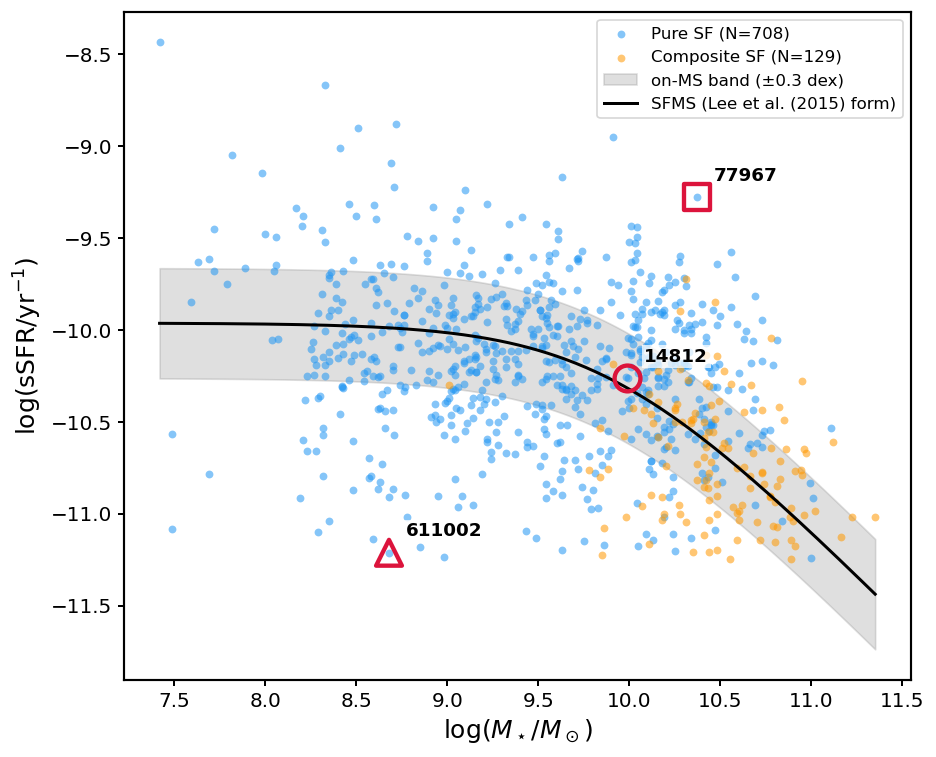

In [3]:
sample = purity.dropna(subset=['log_Mstar', 'log_sSFR'])
print(f"Clean sample: {len(purity)} galaxies, {len(sample)} with log_Mstar and log_sSFR")
print(sample['galclass'].value_counts().sort_index().to_string())

# SFMS line and band in log_Mstar vs log_sSFR space (sSFR_MS = SFR_MS / M*)
mstar_grid = np.linspace(sample['log_Mstar'].min(), sample['log_Mstar'].max(), 300)
ssfr_ms = lee2015_sfms(mstar_grid, *sfms_params) - mstar_grid

def ms_position(delta_ms):
    if pd.isna(delta_ms):
        return 'unknown (no delta_ms)'
    if delta_ms > SFMS_BAND_DEX:
        return 'above the MS'
    if delta_ms < -SFMS_BAND_DEX:
        return 'below the MS'
    return 'on the MS'

fig, ax = plt.subplots(figsize=(8, 6.5))

# Pure SF = galclass 1; composite SF = galclass 2 or 3
CLASS_SPLIT = {'Pure SF': ([1], '#2196F3'), 'Composite SF': ([2, 3], '#FF9800')}
for class_label, (classes, colour) in CLASS_SPLIT.items():
    sub = sample[sample['galclass'].isin(classes)]
    ax.scatter(sub['log_Mstar'], sub['log_sSFR'], s=22, alpha=0.55, c=colour,
               linewidths=0, label=f'{class_label} (N={len(sub)})', zorder=2)

ax.fill_between(mstar_grid, ssfr_ms - SFMS_BAND_DEX, ssfr_ms + SFMS_BAND_DEX,
                color='grey', alpha=0.25, zorder=1, label=f'on-MS band (±{SFMS_BAND_DEX} dex)')
ax.plot(mstar_grid, ssfr_ms, color='black', lw=1.8, zorder=3, label='SFMS (Lee et al. (2015) form)')

markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
highlight_rows = []
for i, catid in enumerate(HIGHLIGHT_CATIDS):
    sel = df[df['CATID'] == catid]
    if sel.empty or sel[['log_Mstar', 'log_sSFR']].isna().any(axis=None):
        print(f'  WARNING: CATID {catid} not in master.csv or has no log_Mstar/log_sSFR - skipping')
        continue
    row = sel.iloc[0]
    ax.scatter(row['log_Mstar'], row['log_sSFR'], s=240, marker=markers[i % len(markers)],
               facecolors='none', edgecolors='crimson', linewidths=2.6, zorder=5)
    ax.annotate(str(catid), (row['log_Mstar'], row['log_sSFR']),
                textcoords='offset points', xytext=(10, 10), fontsize=11, weight='bold',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.75, pad=1.5))
    highlight_rows.append({
        'CATID': catid,
        'log_Mstar': row['log_Mstar'],
        'log_sSFR': row['log_sSFR'],
        'delta_ms': row['delta_ms'],
        'position': ms_position(row['delta_ms']),
        'galclass': row['galclass'],
    })

ax.set_xlabel(r'$\log(M_\star / M_\odot)$')
ax.set_ylabel(r'$\log(\mathrm{sSFR} / \mathrm{yr}^{-1})$')
ax.legend(loc='upper right', fontsize=10)  # highlighted galaxies are labelled on the plot
plt.tight_layout()

OUT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_FIGURE_DIR / 'fig1_sfms.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# Highlighted galaxies: position relative to the SFMS
pd.DataFrame(highlight_rows)

,CATID,log_Mstar,log_sSFR,delta_ms,position,spectral_class
0,14812,9.99,-10.263980,0.052627,on the MS,pure_SF
1,77967,10.37,-9.278574,1.288457,above the MS,pure_SF
2,611002,8.68,-11.212373,-1.223956,below the MS,composite_SF


## Figure 2 — GCAS vs. global properties and ΔMS

**Question this answers:** how does each GCAS parameter individually relate to
stellar mass, sSFR, SFR, and displacement from the star-forming main sequence
(ΔMS)? One row per parameter (G, C, A, S), one column per property — 4×4 grid,
Spearman ρ annotated in each panel. Each parameter uses its own valid-N mask
(`in_G`, `in_C`, `in_A`, `in_S`), since coverage differs slightly between them.

The ΔMS column asks whether each parameter tracks a galaxy's evolutionary
state rather than Mstar and sSFR separately (which are correlated with each
other): ΔMS collapses the Mstar–sSFR plane into one axis (bursting →
main-sequence → quenching). The grey band is the same on-MS band as Figure 1
(±`SFMS_BAND_DEX`), and the x-range is trimmed to the 0.5–99.5 percentiles so
a few extreme values don't squash the panels.

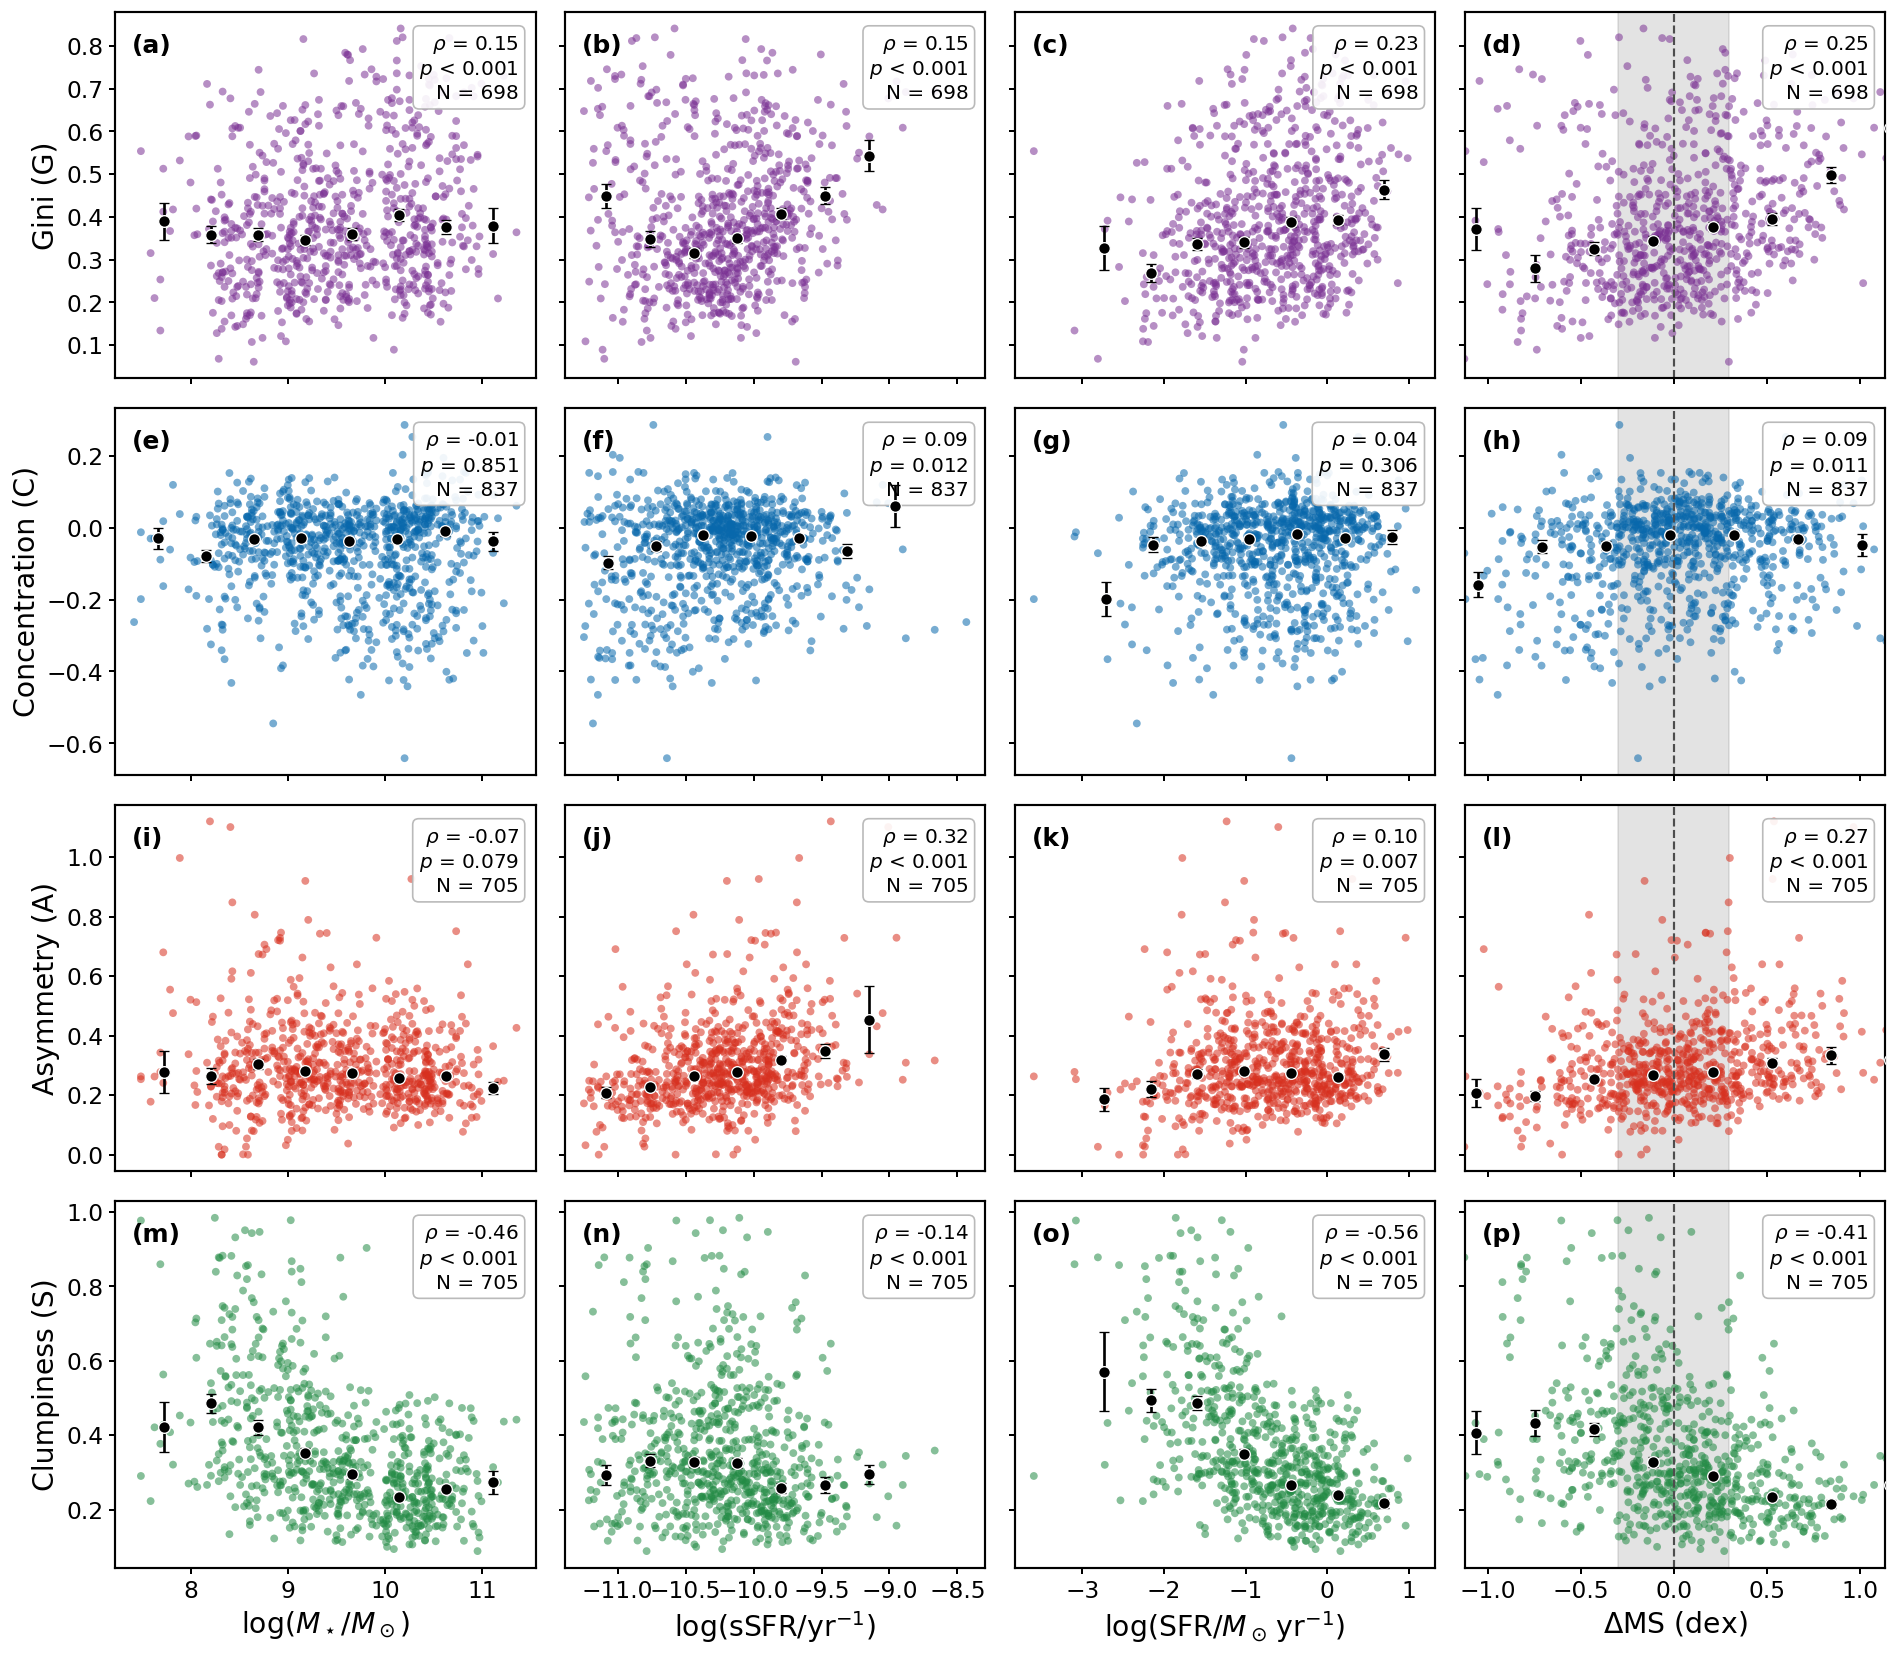

In [26]:
import string
global_props = [
    ('log_Mstar', r'$\log(M_\star / M_\odot)$'),
    ('log_sSFR', r'$\log(\mathrm{sSFR} / \mathrm{yr}^{-1})$'),
    ('log_SFR', r'$\log(\mathrm{SFR} / M_\odot\,\mathrm{yr}^{-1})$'),
    ('delta_ms', r'$\Delta\mathrm{MS}$ (dex)'),
]

# ΔMS x-range: 0.5-99.5 percentiles, so a few extreme values don't squash the panels
dms_xlim = (purity['delta_ms'].quantile(0.005), purity['delta_ms'].quantile(0.995))

# Figure 2 fonts: 2 pt larger than the notebook defaults so they stay
# readable once the figure is shrunk to the page width
FIG2_STYLE = {'axes.labelsize': 17, 'xtick.labelsize': 14, 'ytick.labelsize': 14}

with plt.rc_context(FIG2_STYLE):
    fig, axes = plt.subplots(4, 4, figsize=(16, 14), sharex='col', sharey='row')
    letters = iter(string.ascii_lowercase)

    for i, metric in enumerate(GCAS):
        sub = purity[purity[f'in_{metric}'] == True]
        y = sub[metric].values
        for j, (prop, label) in enumerate(global_props):
            ax = axes[i, j]
            x = sub[prop].values
            if prop == 'delta_ms':
                ax.axvspan(-SFMS_BAND_DEX, SFMS_BAND_DEX, color='0.4', alpha=0.18, zorder=0)
                ax.axvline(0, color='0.3', ls='--', lw=1.3)
                ax.set_xlim(*dms_xlim)
            ax.scatter(x, y, s=22, alpha=0.55, color=GCAS_COLOR[metric], edgecolor='none')
            binned_median_errorbar(ax, x, y, bins=8)
            spearman_annotate(ax, x, y, fontsize=12)
            panel_label(ax, next(letters), fontsize=15)
            if i == 3:
                ax.set_xlabel(label)
            if j == 0:
                ax.set_ylabel(GCAS_LABELS[metric])

    plt.tight_layout()
    fig.savefig(OUT_FIGURE_DIR / 'fig2_gcas_vs_global.png', dpi=300, bbox_inches='tight')
plt.show()

In [27]:
# Spearman significance for Figure 2 (printed, not plotted).
# Same per-metric samples as the plot cell above.
rows = []
for metric in GCAS:
    sub = purity[purity[f'in_{metric}'] == True]
    for prop, _ in global_props:
        rows.append((metric, prop, sub[prop].to_numpy(float), sub[metric].to_numpy(float)))
print_spearman_table(rows, 'Figure 2: Spearman rho vs. global properties and ΔMS')


Figure 2: Spearman rho vs. global properties and ΔMS
metric  vs              rho          p     N  p<0.05
G       log_Mstar      0.15    6.5e-05   698  yes
G       log_sSFR       0.15    4.1e-05   698  yes
G       log_SFR        0.23    4.5e-10   698  yes
G       delta_ms       0.25    1.6e-11   698  yes
C       log_Mstar     -0.01    8.5e-01   837  no
C       log_sSFR       0.09    1.2e-02   837  yes
C       log_SFR        0.04    3.1e-01   837  no
C       delta_ms       0.09    1.1e-02   837  yes
A       log_Mstar     -0.07    7.9e-02   705  no
A       log_sSFR       0.32    1.4e-18   705  yes
A       log_SFR        0.10    6.6e-03   705  yes
A       delta_ms       0.27    4.4e-13   705  yes
S       log_Mstar     -0.46    2.4e-37   705  yes
S       log_sSFR      -0.14    1.5e-04   705  yes
S       log_SFR       -0.56    1.4e-58   705  yes
S       delta_ms      -0.41    2.7e-29   705  yes


In [28]:
# Curvature of G vs log(sSFR) - panel (b) of Figure 2.
# Same sample as the panel: clean sample with a finite Gini value.
import statsmodels.api as sm

fit_df = purity[(purity['in_G'] == True) & np.isfinite(purity['G']) & np.isfinite(purity['log_sSFR'])]
x = fit_df['log_sSFR'].to_numpy()
y = fit_df['G'].to_numpy()
n = len(x)

linear = sm.OLS(y, sm.add_constant(x)).fit()
quad = sm.OLS(y, sm.add_constant(np.column_stack([x, x**2]))).fit()

a, b, c = quad.params
c_err, c_p = quad.bse[2], quad.pvalues[2]
x_min = -b / (2 * c)  # turning point; a minimum when c > 0
delta_aic = linear.aic - quad.aic  # positive favours the quadratic

# The turning point is a ratio of fitted coefficients, so its uncertainty
# comes from a bootstrap (resample galaxies, refit) rather than the fit itself.
rng = np.random.default_rng(42)
n_boot = 2000
x_min_boot = np.empty(n_boot)
for k in range(n_boot):
    idx = rng.integers(0, n, n)
    c2, c1, _ = np.polyfit(x[idx], y[idx], 2)
    x_min_boot[k] = -c1 / (2 * c2)
x_min_err = np.std(x_min_boot)

in_range = x.min() <= x_min <= x.max()

def latex_sci(v):
    mant, exp = f'{v:.1e}'.split('e')
    return f'{mant} \\times 10^{{{int(exp)}}}'

print(f'N = {n},  log(sSFR) range = {x.min():.2f} to {x.max():.2f}')
print(f'Quadratic: G = {a:.3f} + {b:.4f} x + {c:.4f} x^2')
print(f'  c = {c:.3f} ± {c_err:.3f}  (p = {c_p:.1e})')
print(f'  {"minimum" if c > 0 else "maximum"} at log(sSFR) = {x_min:.2f} ± {x_min_err:.2f} '
      f'({"inside" if in_range else "OUTSIDE"} data range; '
      f'{(x < x_min).sum()} galaxies below, {(x > x_min).sum()} above)')
print(f'  ΔAIC (linear - quadratic) = {delta_aic:.1f}')

print('\nSentence:')
print(f'a quadratic was fitted to $G$ as a function of $\\log(\\mathrm{{sSFR}})$, giving a '
      f'curvature coefficient $c = {c:.3f} \\pm {c_err:.3f}$ ($p = {latex_sci(c_p)}$) with a minimum at '
      f'$\\log(\\mathrm{{sSFR}}/\\mathrm{{yr}}^{{-1}}) = {x_min:.2f} \\pm {x_min_err:.2f}$, '
      f'{"within" if in_range else "outside"} the range of the data. This is preferred over a '
      f'linear fit ($\\Delta\\mathrm{{AIC}} = {delta_aic:.1f}$).')


N = 698,  log(sSFR) range = -11.25 to -8.67
Quadratic: G = 15.219 + 2.8683 x + 0.1385 x^2
  c = 0.138 ± 0.021  (p = 1.1e-10)
  minimum at log(sSFR) = -10.36 ± 0.06 (inside data range; 253 galaxies below, 445 above)
  ΔAIC (linear - quadratic) = 39.8

Sentence:
a quadratic was fitted to $G$ as a function of $\log(\mathrm{sSFR})$, giving a curvature coefficient $c = 0.138 \pm 0.021$ ($p = 1.1 \times 10^{-10}$) with a minimum at $\log(\mathrm{sSFR}/\mathrm{yr}^{-1}) = -10.36 \pm 0.06$, within the range of the data. This is preferred over a linear fit ($\Delta\mathrm{AIC} = 39.8$).


## Figure 3 — GCAS vs. environment (categorical, mass-controlled)

**Question this answers:** does local environment (isolated / satellite /
central) shift the distribution of each GCAS parameter, once stellar mass is
controlled for? Following Wang (2022, Fig. 8), galaxies are compared within
fixed stellar-mass slices rather than letting Mstar vary freely (which would
confound the comparison).

GAMA-only subsample (`environment == 'GAMA'`), split by `group_status`, in two
slices: $9.5 < \log(M_\star/M_\odot) \leq 10.5$ (top row) and
$8.5 < \log(M_\star/M_\odot) \leq 9.5$ (bottom row). Each metric uses its own
valid-N mask (`in_G`, ...), so N differs slightly between columns; the
per-panel counts are printed below the figure.

Histograms show the fraction of each environment group per bin, with the same
bin edges for every group and both rows within a column. The p-values in each
panel are from two-sample Kolmogorov–Smirnov (K–S) tests between each pair of
environment groups (I = isolated, S = satellite, C = central), testing whether
the two groups share the same distribution (D and exact p printed below).

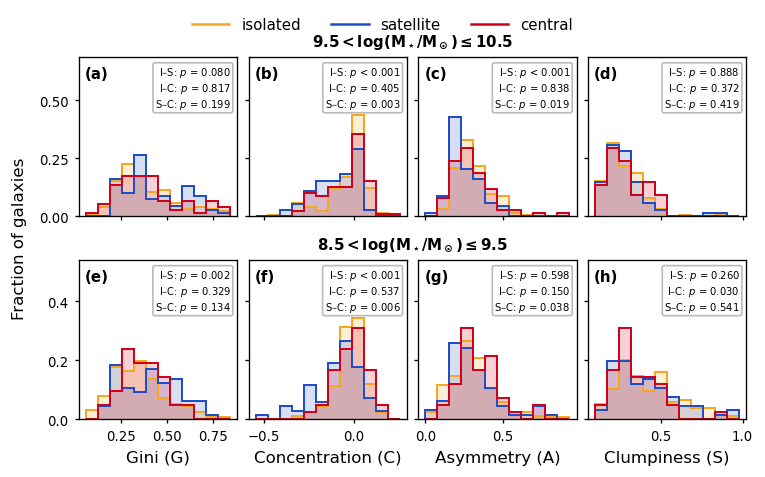

,mass_slice,metric,pair,D,p,N_isolated,N_satellite,N_central
0,9.5-10.5,G,I–S,0.187,0.079654,124.0,68.0,NaN
1,9.5-10.5,G,I–C,0.088,0.817346,124.0,NaN,75.0
2,9.5-10.5,G,S–C,0.174,0.198936,NaN,68.0,75.0
3,9.5-10.5,C,I–S,0.302,0.000361,124.0,72.0,NaN
4,9.5-10.5,C,I–C,0.124,0.404762,124.0,NaN,79.0
5,9.5-10.5,C,S–C,0.285,0.003233,NaN,72.0,79.0
6,9.5-10.5,A,I–S,0.321,0.000159,124.0,68.0,NaN
7,9.5-10.5,A,I–C,0.086,0.837830,124.0,NaN,75.0
8,9.5-10.5,A,S–C,0.249,0.018703,NaN,68.0,75.0
9,9.5-10.5,S,I–S,0.083,0.888060,124.0,68.0,NaN


In [2]:
import itertools
import string

mass_slices = [(9.5, 10.5), (8.5, 9.5)]
gama_only = purity[purity['environment'] == 'GAMA'].copy()

status_order = ['isolated', 'satellite', 'central']
status_color = {'isolated': '#F5A623', 'satellite': '#1F4EC7', 'central': '#D0021B'}
status_ls = {'isolated': '-', 'satellite': '-', 'central': '-'}
STATUS_ABBR = {'isolated': 'I', 'satellite': 'S', 'central': 'C'}
N_BINS = 12
MIN_GROUP_N = 5   # groups smaller than this are not plotted or tested

def slice_galaxies(lo, hi, metric):
    sl = gama_only[(gama_only['log_Mstar'] > lo) & (gama_only['log_Mstar'] <= hi)]
    return sl[(sl[f'in_{metric}'] == True) & sl[metric].notna()]

# Same bin edges for every group and both mass slices within a column
bin_edges = {}
for metric in GCAS:
    vals = pd.concat([slice_galaxies(lo, hi, metric)[metric] for lo, hi in mass_slices])
    bin_edges[metric] = np.linspace(vals.min(), vals.max(), N_BINS + 1)

# Drawn at the printed size (6.3 in = full text width), so font sizes are the
# true sizes in the thesis
FIG3_STYLE = {
    'axes.labelsize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 2.5,
    'ytick.major.size': 2.5,
}

test_rows = []
with plt.rc_context(FIG3_STYLE):
    fig, axes = plt.subplots(2, 4, figsize=(6.3, 3.9), sharex='col', sharey='row')
    letters = iter(string.ascii_lowercase)

    for i, (lo, hi) in enumerate(mass_slices):
        for j, metric in enumerate(GCAS):
            ax = axes[i, j]
            m = slice_galaxies(lo, hi, metric)
            groups = {}
            for status in status_order:
                vals = m.loc[m['group_status'] == status, metric].to_numpy(float)
                if len(vals) < MIN_GROUP_N:
                    continue
                groups[status] = vals
                weights = np.full(len(vals), 1 / len(vals))   # fraction of the group per bin
                ax.hist(vals, bins=bin_edges[metric], weights=weights, histtype='stepfilled',
                        facecolor=status_color[status], alpha=0.18, zorder=1)
                ax.hist(vals, bins=bin_edges[metric], weights=weights, histtype='step',
                        edgecolor=status_color[status], lw=1.2, linestyle=status_ls[status], zorder=2)

            # Two-sample K-S test for each pair of groups present in this panel
            p_lines = []
            for a, b in itertools.combinations(status_order, 2):
                if a not in groups or b not in groups:
                    continue
                D, p = stats.ks_2samp(groups[a], groups[b])
                pair = f'{STATUS_ABBR[a]}–{STATUS_ABBR[b]}'
                test_rows.append({'mass_slice': f'{lo}-{hi}', 'metric': metric, 'pair': pair,
                                  'D': D, 'p': p, f'N_{a}': len(groups[a]), f'N_{b}': len(groups[b])})
                p_lines.append(f'{pair}: {format_p(p)}')
            ax.text(0.96, 0.95, '\n'.join(p_lines), transform=ax.transAxes, ha='right', va='top',
                    fontsize=6, linespacing=1.2,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='0.7', alpha=0.9))
            panel_label(ax, next(letters), fontsize=9)

            if i == len(mass_slices) - 1:
                ax.set_xlabel(GCAS_LABELS[metric])

    # Headroom so the tallest bars sit below the panel letter and p-value box
    for i in range(len(mass_slices)):
        lo_y, hi_y = axes[i, 0].get_ylim()
        axes[i, 0].set_ylim(0, hi_y * 1.5)

    fig.supylabel('Fraction of galaxies', fontsize=10, x=0.01)
    handles = [plt.Line2D([], [], color=status_color[s], ls=status_ls[s], lw=1.5, label=s)
               for s in status_order]
    fig.legend(handles=handles, loc='upper center', ncol=3, fontsize=9, frameon=False,
               bbox_to_anchor=(0.5, 1.0), handlelength=2.5)

    plt.tight_layout(pad=0.3, h_pad=1.6, w_pad=0.3, rect=(0.02, 0, 1, 0.90))

    # Mass slice as a heading centred above each row
    for i, (lo, hi) in enumerate(mass_slices):
        left, right = axes[i, 0].get_position(), axes[i, -1].get_position()
        fig.text((left.x0 + right.x1) / 2, left.y1 + 0.012,
                 f'$\\mathbf{{{lo} < log(M_\\star/M_\\odot) \\leq {hi}}}$',   # bold heading
                 ha='center', va='bottom', fontsize=9)
    fig.savefig(OUT_FIGURE_DIR / 'fig3_environment.png', dpi=300, bbox_inches='tight')
plt.show()

# Pairwise K-S results and group sizes for each panel
ks_cols = ['mass_slice', 'metric', 'pair', 'D', 'p'] + [f'N_{s}' for s in status_order]
pd.DataFrame(test_rows)[ks_cols].round({'D': 3})

In [ ]:
# Mean ± SEM (N) of each GCAS parameter per mass slice and environment group.
# Same galaxies as Figure 3 (slice_galaxies), but groups with N < MIN_GROUP_N
# are kept here, so check N before reading much into small groups.
rows = []
for lo, hi in mass_slices:
    for metric in GCAS:
        m = slice_galaxies(lo, hi, metric)
        for status in status_order:
            vals = m.loc[m['group_status'] == status, metric].to_numpy(float)
            n = len(vals)
            rows.append({'mass_slice': f'{lo}-{hi}', 'environment': status, 'metric': metric,
                         'mean': vals.mean() if n else np.nan,
                         'sem': stats.sem(vals) if n > 1 else np.nan,
                         'N': n})
env_means = pd.DataFrame(rows)   # long form, e.g. env_means.query("metric == 'A'")

def fmt_mean(r):
    if r['N'] == 0:
        return '—'
    if np.isnan(r['sem']):
        return f"{r['mean']:.3f} (N={r['N']})"
    return f"{r['mean']:.3f} ± {r['sem']:.3f} (N={r['N']})"

row_order = pd.MultiIndex.from_product([[f'{lo}-{hi}' for lo, hi in mass_slices], status_order],
                                       names=['mass_slice', 'environment'])
env_table = (env_means.assign(value=env_means.apply(fmt_mean, axis=1))
             .pivot(index=['mass_slice', 'environment'], columns='metric', values='value')
             .reindex(row_order)[GCAS])
env_table

## Figure 4 — The sSFR–M★ plane coloured by each GCAS parameter

**Question this answers:** where in the sSFR–M★ plane do galaxies with high or
low G, C, A and S sit relative to the SFMS? Same clean sample (`in_full_sam`),
SFMS fit and ±`SFMS_BAND_DEX` band as Figure 1; each panel uses its own
valid-N mask (`in_G`, `in_C`, `in_A`, `in_S`). The colour scale in each panel
runs from the 5th to the 95th percentile of that parameter, so a few outliers
don't wash out the colours.

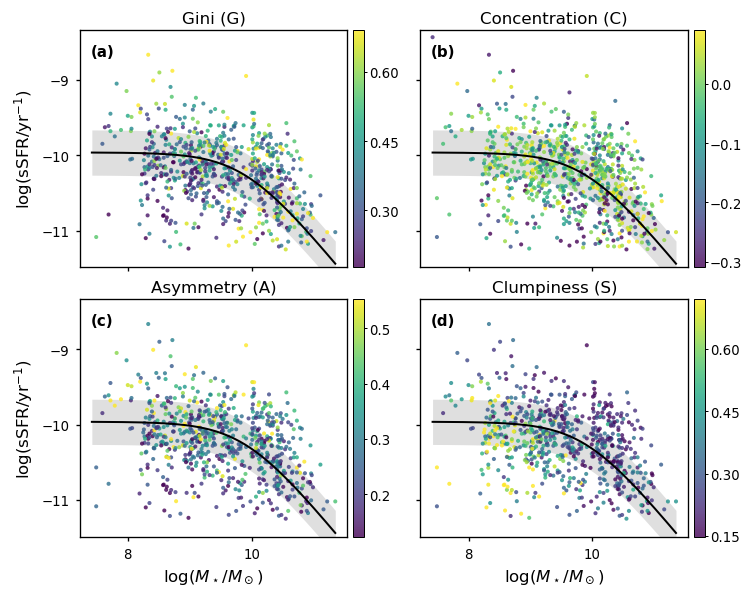

In [43]:
import string
from matplotlib.ticker import MaxNLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable

# SFMS line and band in log_Mstar vs log_sSFR space, as in Figure 1, drawn from
# the least to the most massive galaxy
mstar_grid = np.linspace(purity['log_Mstar'].min(), purity['log_Mstar'].max(), 300)
ssfr_ms = lee2015_sfms(mstar_grid, *sfms_params) - mstar_grid

# Drawn at the printed size (6.3 in = full text width), so font sizes are the
# true sizes in the thesis
FIG4_STYLE = {
    'axes.labelsize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 2.5,
    'ytick.major.size': 2.5,
}

with plt.rc_context(FIG4_STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(6.3, 4.9), sharex=True, sharey=True)
    letters = iter(string.ascii_lowercase)

    for ax, metric in zip(axes.flat, GCAS):
        sub = purity[(purity[f'in_{metric}'] == True) & purity[metric].notna()]
        vmin, vmax = np.percentile(sub[metric], [5, 95])

        ax.fill_between(mstar_grid, ssfr_ms - SFMS_BAND_DEX, ssfr_ms + SFMS_BAND_DEX,
                        color='grey', alpha=0.25, lw=0, zorder=1)
        sc = ax.scatter(sub['log_Mstar'], sub['log_sSFR'], c=sub[metric], cmap='viridis',
                        vmin=vmin, vmax=vmax, s=6, alpha=0.8, linewidths=0, zorder=2)
        ax.plot(mstar_grid, ssfr_ms, color='black', lw=1.2, zorder=3)
        panel_label(ax, next(letters), fontsize=9)
        ax.set_title(GCAS_LABELS[metric], fontsize=10, pad=4)

        # Colourbar on the right of the panel (the metric is named in the panel title)
        cax = make_axes_locatable(ax).append_axes('right', size='4%', pad=0.05)
        cbar = fig.colorbar(sc, cax=cax)
        cbar.ax.yaxis.set_major_locator(MaxNLocator(5))
        cbar.ax.tick_params(labelsize=8, width=0.6, length=2, pad=1)
        cbar.outline.set_linewidth(0.6)

    # y-range set by the galaxies and the SFMS line, not the SFMS band (which
    # extends well below the data at high mass), to avoid empty space at the
    # bottom of each panel while keeping the whole line visible
    y_lo = min(purity['log_sSFR'].min(), ssfr_ms.min())
    y_hi = purity['log_sSFR'].max()
    axes[0, 0].set_ylim(y_lo - 0.05, y_hi + 0.1)

    for ax in axes[-1, :]:
        ax.set_xlabel(r'$\log(M_\star / M_\odot)$')
    for ax in axes[:, 0]:
        ax.set_ylabel(r'$\log(\mathrm{sSFR} / \mathrm{yr}^{-1})$')

    plt.tight_layout(pad=0.3, h_pad=0.4, w_pad=0.8)
    fig.savefig(OUT_FIGURE_DIR / 'fig4_sfms_by_metric.png', dpi=300, bbox_inches='tight')
plt.show()